# 09 · Safety Head CT Scan EDA
> *CT scans performed as a safety check before lumbar punctures — a routine procedural requirement in PPMI.*

## Background: Why CT Scans for Safety?

PPMI collects **cerebrospinal fluid (CSF)** via lumbar puncture (spinal tap) as part of its biomarker program. CSF contains valuable protein markers (alpha-synuclein, tau, etc.) that complement the imaging data.

Before performing a lumbar puncture, clinicians must ensure there is **no raised intracranial pressure** — a condition where the CT scan shows brain swelling or herniation risk. If there's a problem, the LP is contraindicated.

**The CT scan here is not for brain analysis** — it's a standard safety screening tool.

**What is a CT scan?**
CT (Computed Tomography) uses X-rays from multiple angles to create cross-sectional images of the brain. It's faster and cheaper than MRI but provides less soft-tissue detail.

---

## Column Reference

| Column | Meaning |
|--------|---------|
| `PATNO` | Participant ID |
| `EVENT_ID` | Visit code when CT was done |
| `CTSCAN` | CT scan completed: 1=Yes, 0=No |
| `CTDT` | Date of CT scan (MM/DD/YYYY or MM/YYYY) |
| `PAG_NAME` | Form identifier (always "CT") |
| `REC_ID` | Unique record identifier |
| `ORIG_ENTRY` | Date data was first entered into the system |
| `LAST_UPDATE` | Date data was most recently updated |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data File

In [3]:
ct = pd.read_csv(DATA_DIR / 'Safety_Head_CT_Scan_12Nov2026.csv')
print(f'Shape: {ct.shape}')
print(f'Participants: {ct["PATNO"].nunique()}')
print(f'Completion (1=Yes, 0=No):')
print(ct['CTSCAN'].value_counts())
ct.head()

Shape: (958, 8)
Participants: 958
Completion (1=Yes, 0=No):
CTSCAN
0    956
1      2
Name: count, dtype: int64


,REC_ID,PATNO,EVENT_ID,PAG_NAME,CTSCAN,CTDT,ORIG_ENTRY,LAST_UPDATE
0,IA1186620,103583,SC,CT,0,NaN,09/2026,2026-09-17
1,IA932826,103924,SC,CT,0,NaN,01/2026,2026-01-29
2,IA1138914,106809,SC,CT,0,NaN,07/2026,2026-07-27
3,IA712248,106947,SC,CT,0,NaN,04/2025,2025-04-02
4,IA865162,108580,SC,CT,0,NaN,10/2025,2025-10-29


## 1 · CT Scan Completion Rate by Visit

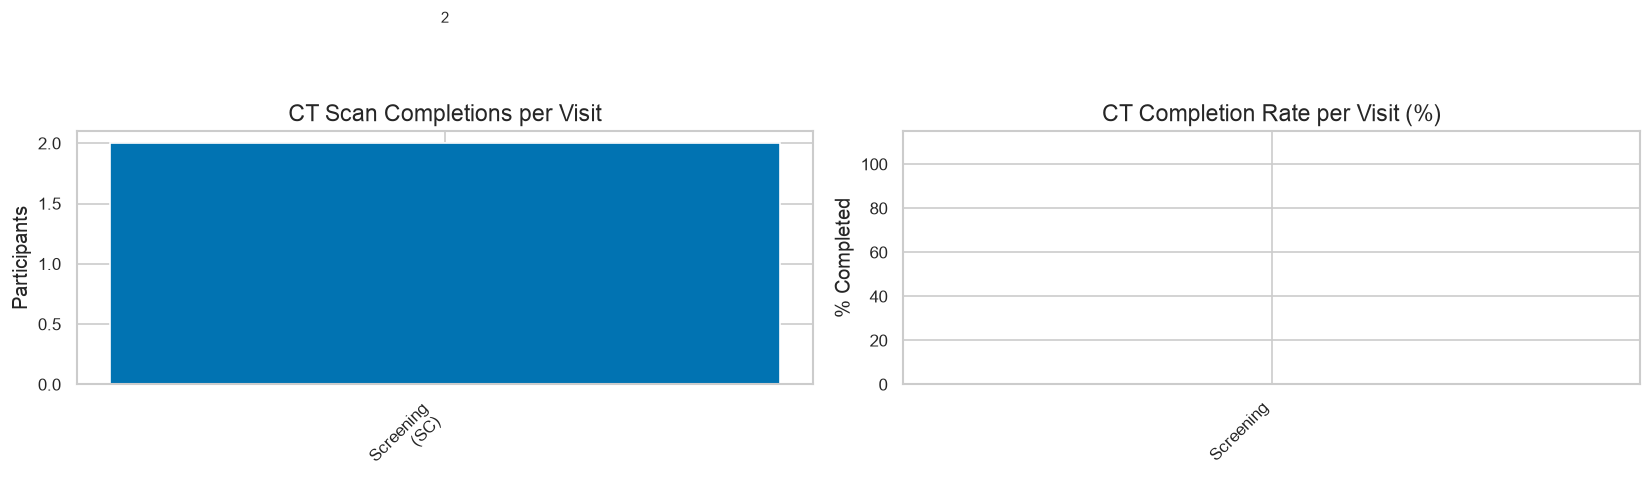

In [4]:
visits = ordered_visits(ct['EVENT_ID'])
done = ct[ct['CTSCAN'] == 1]
vc = done.groupby('EVENT_ID')['PATNO'].nunique().reindex(visits).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Completed count
bars = axes[0].bar(range(len(vc)), vc.values, color=sns.color_palette('colorblind')[0])
axes[0].set_xticks(range(len(vc)))
axes[0].set_xticklabels([f'{VISIT_LABELS.get(v,v)}\n({v})' for v in vc.index], rotation=45, ha='right')
axes[0].set_ylabel('Participants'); axes[0].set_title('CT Scan Completions per Visit')
for b, v in zip(bars, vc.values):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+1, str(int(v)), ha='center', fontsize=9)

# Overall completion rate
total_per_visit = ct.groupby('EVENT_ID')['PATNO'].nunique().reindex(visits).dropna()
rate = (vc / total_per_visit * 100).dropna()
axes[1].bar(range(len(rate)), rate.values, color=sns.color_palette('colorblind')[1])
axes[1].set_xticks(range(len(rate)))
axes[1].set_xticklabels([VISIT_LABELS.get(v,v) for v in rate.index], rotation=45, ha='right')
axes[1].set_ylabel('% Completed'); axes[1].set_title('CT Completion Rate per Visit (%)')
axes[1].set_ylim(0, 115)
plt.tight_layout(); plt.show()

## 2 · CT Completion Over Calendar Time

In [5]:
ct_done = ct[ct['CTSCAN'] == 1].copy()
if 'ORIG_ENTRY' in ct_done.columns:
    ct_done['ENTRY_DATE'] = pd.to_datetime(ct_done['ORIG_ENTRY'], errors='coerce', format='%m/%Y')
    if ct_done['ENTRY_DATE'].isna().mean() > 0.5:
        ct_done['ENTRY_DATE'] = pd.to_datetime(ct_done['ORIG_ENTRY'], errors='coerce')

    ct_done = ct_done.dropna(subset=['ENTRY_DATE'])
    if len(ct_done) > 10:
        ct_done['Year'] = ct_done['ENTRY_DATE'].dt.year
        yearly = ct_done.groupby('Year').size()

        fig, ax = plt.subplots(figsize=(12, 5))
        ax.bar(yearly.index, yearly.values, color=sns.color_palette('colorblind')[2])
        ax.set_title('CT Scans Completed by Year of Entry')
        ax.set_xlabel('Year'); ax.set_ylabel('CT Scans Completed')
        ax.set_xticks(yearly.index)
        plt.tight_layout(); plt.show()

## 3 · Missing Data Analysis

In [6]:
missing = (ct.isnull().sum() / len(ct) * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False)
print('Columns with missing data:')
print(missing.to_string())
print(f'\nTotal records: {len(ct):,}')
print(f'Records with CT completed: {(ct["CTSCAN"]==1).sum():,} ({(ct["CTSCAN"]==1).mean()*100:.1f}%)')
print(f'Records with CT not done: {(ct["CTSCAN"]==0).sum():,}')
print(f'Records with missing CT date (CTDT): {ct["CTDT"].isna().sum():,}')

Columns with missing data:
CTDT    99.8

Total records: 958
Records with CT completed: 2 (0.2%)
Records with CT not done: 956
Records with missing CT date (CTDT): 956


## Key Takeaways

- **Safety CT is a procedural requirement** for lumbar puncture, not a brain imaging biomarker
- **Most records (~958) represent screening visits** — LP safety check is typically done early
- **High completion rate** where CT was scheduled — consistent with the safety-critical nature
- **Missing CTDT** likely reflects records where CT was not required or was done previously
- **This dataset is best used** as a flag: which participants underwent LP (and therefore have CSF biomarker data available)?